<a href="https://colab.research.google.com/github/Oleh12342/pattern-recognition-practice/blob/model-comparison/classification-mini-project/notebooks/PR04_Kulesh_O.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Підключення Google-Drive

In [51]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [52]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/classification-mini-project")
DATA_DIR    = PROJECT_DIR / "data"
MODELS_DIR  = PROJECT_DIR / "models"
REPORTS_DIR = PROJECT_DIR / "reports"

MODELS_DIR.mkdir(exist_ok=True)
REPORTS_DIR.mkdir(exist_ok=True)

print(list(DATA_DIR.iterdir()))

[PosixPath('/content/drive/MyDrive/classification-mini-project/data/processed.cleveland.data'), PosixPath('/content/drive/MyDrive/classification-mini-project/data/heart_disease.csv')]


## Створення heart_disease.csv
Готового файлу heart_disease.csv не було, тому я створив його самостійно з оригінального архіву UCI Heart Disease. Використано файл processed.cleveland.data.

In [53]:
import pandas as pd

columns = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"
]

df = pd.read_csv(
    DATA_DIR / "processed.cleveland.data",
    header=None,
    names=columns,
    na_values="?"
)

df["target"] = (df["num"] > 0).astype(int)
df = df.drop(columns="num")

print(df.shape)
print(df["target"].value_counts())
print(df.isna().sum().sum())

df.to_csv(DATA_DIR / "heart_disease.csv", index=False)

(303, 14)
target
0    164
1    139
Name: count, dtype: int64
6


# Частина 1
Основна метрика: F1 для позитивного класу; додаткові: Recall, ROC AUC.

Імпорт бібліотек та константи

In [54]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

RANDOM_STATE = 42

numeric_columns = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_columns = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
target_column = "target"

Завантаження та аудит

In [55]:
df = pd.read_csv(DATA_DIR / "heart_disease.csv")

display(df.head())
print("Розмір:", df.shape)
print("\nТипи даних:")
print(df.dtypes)
print("\nПропуски по стовпцях:")
print(df.isna().sum())
print("\nРозподіл класів:")
print(df[target_column].value_counts())
print(df[target_column].value_counts(normalize=True).round(3))
print("\nДопустимі значення target:", sorted(df[target_column].unique()))

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


Розмір: (303, 14)

Типи даних:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object

Пропуски по стовпцях:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Розподіл класів:
target
0    164
1    139
Name: count, dtype: int64
target
0    0.541
1    0.459
Name: proportion, dtype: float64

Допустимі значення target: [np.int64(0), np.int64(1)]


In [56]:
audit = pd.DataFrame({
    "Характеристика": [
        "Кількість об'єктів", "Кількість вхідних ознак",
        "Числові ознаки", "Категоріальні ознаки",
        "Кількість пропусків", "Кількість класів", "Позитивний клас"
    ],
    "Значення": [
        df.shape[0], df.shape[1] - 1,
        ", ".join(numeric_columns), ", ".join(categorical_columns),
        int(df.isna().sum().sum()), df[target_column].nunique(), 1
    ]
})
display(audit)

,Характеристика,Значення
0,Кількість об'єктів,303
1,Кількість вхідних ознак,13
2,Числові ознаки,"age, trestbps, chol, thalach, oldpeak"
3,Категоріальні ознаки,"sex, cp, fbs, restecg, exang, slope, ca, thal"
4,Кількість пропусків,6
5,Кількість класів,2
6,Позитивний клас,1


X, y і єдиний split

In [57]:
X = df.drop(columns=target_column)
y = df[target_column]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Частка класу 1 у train:", round(y_train.mean(), 3))
print("Частка класу 1 у test: ", round(y_test.mean(), 3))

Train: (242, 13)  Test: (61, 13)
Частка класу 1 у train: 0.459
Частка класу 1 у test:  0.459


Єдина схема крос-валідації


In [58]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Препроцесинг

In [59]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

numeric_pipeline_scaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

numeric_pipeline_raw = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", "passthrough")
])

preprocessor_scaled = ColumnTransformer([
    ("num", numeric_pipeline_scaled, numeric_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

preprocessor_raw = ColumnTransformer([
    ("num", numeric_pipeline_raw, numeric_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

Два Pipeline логістичної регресії та порівняння за CV

In [60]:
lr_scaled = Pipeline([
    ("preprocessor", preprocessor_scaled),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])

lr_raw = Pipeline([
    ("preprocessor", preprocessor_raw),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])

scoring = {"f1": "f1", "roc_auc": "roc_auc", "recall": "recall"}

def run_cv(pipeline, name):
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        res = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
        n_warn = sum("converge" in str(x.message).lower() for x in w)
    fitted = pipeline.fit(X_train, y_train)
    n_iter = int(fitted.named_steps["classifier"].n_iter_[0])
    return {
        "Модель": name,
        "CV F1": res["test_f1"].mean(), "F1 std": res["test_f1"].std(),
        "CV ROC AUC": res["test_roc_auc"].mean(), "AUC std": res["test_roc_auc"].std(),
        "CV Recall": res["test_recall"].mean(),
        "Ітерацій (train)": n_iter,
        "Попередж. збіжності": n_warn,
    }

scale_cmp = pd.DataFrame([
    run_cv(lr_raw, "LogReg без стандартизації"),
    run_cv(lr_scaled, "LogReg зі стандартизацією"),
]).round(4)
display(scale_cmp)

,Модель,CV F1,F1 std,CV ROC AUC,AUC std,CV Recall,Ітерацій (train),Попередж. збіжності
0,LogReg без стандартизації,0.8245,0.0069,0.8997,0.0157,0.7834,1238,0
1,LogReg зі стандартизацією,0.8245,0.0069,0.9025,0.0144,0.7834,18,0


L1- і L2-регуляризація

In [61]:
param_grid = [
    {"classifier__penalty": ["l1", "l2"],
     "classifier__C": [0.01, 0.1, 1, 10, 100]}
]

lr_grid_pipe = Pipeline([
    ("preprocessor", preprocessor_scaled),
    ("classifier", LogisticRegression(solver="liblinear", max_iter=2000, random_state=RANDOM_STATE))
])

grid_lr = GridSearchCV(
    lr_grid_pipe, param_grid,
    scoring="f1", cv=cv, n_jobs=-1, refit=True,
    return_train_score=False
)
grid_lr.fit(X_train, y_train)

print("Найкращі параметри:", grid_lr.best_params_)
print("Найкращий CV F1:", round(grid_lr.best_score_, 4))

lr_results = (pd.DataFrame(grid_lr.cv_results_)
    [["param_classifier__penalty", "param_classifier__C",
      "mean_test_score", "std_test_score", "rank_test_score"]]
    .rename(columns={
        "param_classifier__penalty": "penalty",
        "param_classifier__C": "C",
        "mean_test_score": "CV F1",
        "std_test_score": "CV F1 std",
        "rank_test_score": "rank"})
    .sort_values("rank"))
display(lr_results.round(4))

Найкращі параметри: {'classifier__C': 10, 'classifier__penalty': 'l2'}
Найкращий CV F1: 0.8363


,penalty,C,CV F1,CV F1 std,rank
7,l2,10.00,0.8363,0.0127,1
8,l1,100.00,0.8363,0.0127,1
9,l2,100.00,0.8363,0.0127,1
6,l1,10.00,0.8321,0.0108,4
5,l2,1.00,0.8245,0.0069,5
3,l2,0.10,0.8140,0.0299,6
4,l1,1.00,0.8123,0.0173,7
2,l1,0.10,0.7926,0.0306,8
1,l2,0.01,0.7658,0.0171,9
0,l1,0.01,0.0000,0.0000,10


Графік залежності CV F1 від C

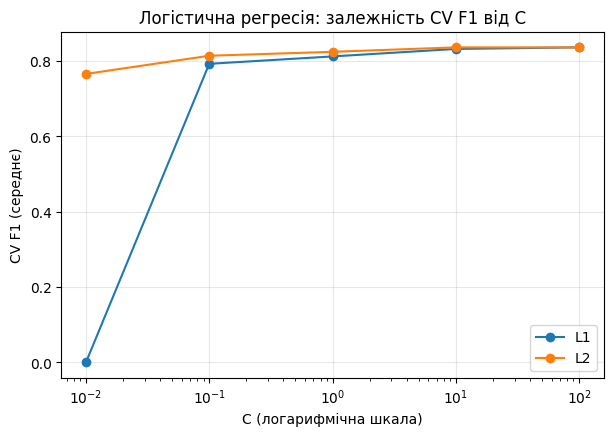

In [62]:
plt.figure(figsize=(7, 4.5))
for pen in ["l1", "l2"]:
    sub = lr_results[lr_results["penalty"] == pen].sort_values("C")
    plt.plot(sub["C"].astype(float), sub["CV F1"], marker="o", label=pen.upper())
plt.xscale("log")
plt.xlabel("C (логарифмічна шкала)")
plt.ylabel("CV F1 (середнє)")
plt.title("Логістична регресія: залежність CV F1 від C")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Топ-5 коефіцієнтів найкращої моделі

In [63]:
best_lr = grid_lr.best_estimator_
feature_names = best_lr.named_steps["preprocessor"].get_feature_names_out()
coefs = best_lr.named_steps["classifier"].coef_[0]

coef_df = pd.DataFrame({
    "Ознака": feature_names,
    "Коефіцієнт": coefs,
    "|Коефіцієнт|": np.abs(coefs)
}).sort_values("|Коефіцієнт|", ascending=False)

display(coef_df.head(5).round(4))

,Ознака,Коефіцієнт,|Коефіцієнт|
21,cat__ca_0.0,-1.9262,1.9262
10,cat__cp_4.0,1.1886,1.1886
27,cat__thal_7.0,0.9779,0.9779
7,cat__cp_1.0,-0.8921,0.8921
5,cat__sex_0.0,-0.8802,0.8802


## Висновок
Побудовано Pipeline (імпутація, стандартизація, one-hot-кодування) і досліджено логістичну регресію за 5-кратною StratifiedKFold лише на train; тестова вибірка не використовувалася.

- **Масштабування:** CV F1 (0,8245) і Recall (0,7834) не змінилися, ROC AUC майже однаковий (0,9025 проти 0,8997). Різниця у збіжності: 18 ітерацій зі стандартизацією проти 1238 без неї, тому далі використовуємо стандартизацію.
- **Регуляризація:** найкраща конфігурація за CV: L2, C = 10 (CV F1 = 0,8363, std = 0,0127). За C = 0,01 L1 занулює всі коефіцієнти (F1 = 0, недонавчання), а за C ≥ 10 якість виходить на плато.
- **Коефіцієнти:** найбільші за модулем мають ca = 0 (-1,93), cp = 4 (+1,19), thal = 7 (+0,98), cp = 1 (-0,89), sex = ` (-0,88). Вони описують закономірності в даних, але не доводять причинного впливу.

# Частина 2

Імпорти, допоміжна функція і результат логістичної регресії з частини 1

In [64]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.model_selection import cross_val_predict

cv_rows = []

def cv_summary(pipeline, name, params="", n_jobs=-1):
    res = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=n_jobs)
    return {
        "Модель": name, "Параметри": params,
        "CV F1": res["test_f1"].mean(), "CV F1 std": res["test_f1"].std(),
        "CV Recall": res["test_recall"].mean(),
        "CV ROC AUC": res["test_roc_auc"].mean(),
        "Час fit, с": res["fit_time"].mean(),
    }

cv_rows.append(cv_summary(grid_lr.best_estimator_, "Logistic Regression", "L2, C=10"))
display(pd.DataFrame(cv_rows).round(4))

,Модель,Параметри,CV F1,CV F1 std,CV Recall,CV ROC AUC,"Час fit, с"
0,Logistic Regression,"L2, C=10",0.8363,0.0127,0.8016,0.9002,0.0287


k-NN

In [65]:
def make_knn(preprocessor, **kw):
    return Pipeline([("preprocessor", preprocessor),
                     ("classifier", KNeighborsClassifier(**kw))])

knn_scale_cmp = pd.DataFrame([
    cv_summary(make_knn(preprocessor_raw, n_neighbors=5), "k-NN без стандартизації", "k=5"),
    cv_summary(make_knn(preprocessor_scaled, n_neighbors=5), "k-NN зі стандартизацією", "k=5"),
])
display(knn_scale_cmp.round(4))

,Модель,Параметри,CV F1,CV F1 std,CV Recall,CV ROC AUC,"Час fit, с"
0,k-NN без стандартизації,k=5,0.5120,0.0134,0.4866,0.6419,0.0259
1,k-NN зі стандартизацією,k=5,0.7989,0.0426,0.7826,0.8712,0.0303


Вибір k (3, 5, 7, 9, 11, 15) і графік

,k,CV F1,CV F1 std,CV ROC AUC,CV Recall
0,3,0.8042,0.0272,0.8709,0.8008
1,5,0.7989,0.0426,0.8712,0.7826
2,7,0.7942,0.0184,0.8721,0.7656
3,9,0.7872,0.0294,0.8744,0.7557
4,11,0.7791,0.0273,0.8806,0.7375
5,15,0.7651,0.0246,0.8729,0.7209


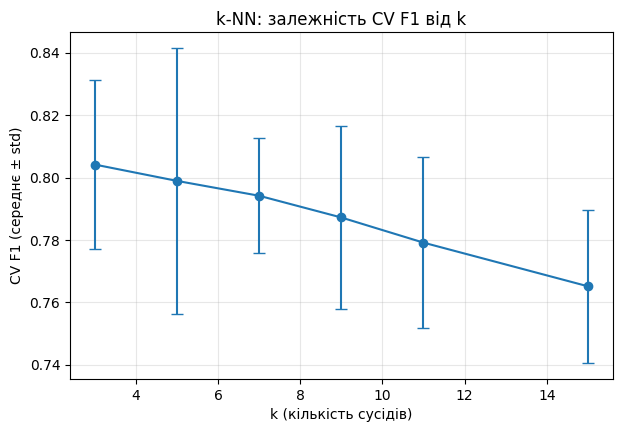

Найкраще k за CV F1: 3


In [66]:
k_values = [3, 5, 7, 9, 11, 15]
knn_k_df = pd.DataFrame([
    {**cv_summary(make_knn(preprocessor_scaled, n_neighbors=k), f"k-NN k={k}", f"k={k}"), "k": k}
    for k in k_values
])
display(knn_k_df[["k", "CV F1", "CV F1 std", "CV ROC AUC", "CV Recall"]].round(4))

plt.figure(figsize=(7, 4.5))
plt.errorbar(knn_k_df["k"], knn_k_df["CV F1"], yerr=knn_k_df["CV F1 std"],
             marker="o", capsize=4)
plt.xlabel("k (кількість сусідів)")
plt.ylabel("CV F1 (середнє ± std)")
plt.title("k-NN: залежність CV F1 від k")
plt.grid(alpha=0.3)
plt.show()

best_k = int(knn_k_df.loc[knn_k_df["CV F1"].idxmax(), "k"])
print("Найкраще k за CV F1:", best_k)

Евклідова та манхеттенська відстань для найкращого k

In [67]:
dist_rows = []
for metric, label in [("euclidean", "Евклідова"), ("manhattan", "Мангеттенська")]:
    row = cv_summary(make_knn(preprocessor_scaled, n_neighbors=best_k, metric=metric),
                     f"k-NN ({label})", f"k={best_k}, metric={metric}")
    row["Міра відстані"] = label
    dist_rows.append(row)

dist_df = pd.DataFrame(dist_rows)
display(dist_df[["Міра відстані", "CV F1", "CV F1 std", "CV ROC AUC"]].round(4))

best_knn_row = dist_df.loc[dist_df["CV F1"].idxmax()]
best_metric = "euclidean" if best_knn_row["Міра відстані"] == "Евклідова" else "manhattan"
best_knn_pipe = make_knn(preprocessor_scaled, n_neighbors=best_k, metric=best_metric)
cv_rows.append(cv_summary(best_knn_pipe, "k-NN", f"k={best_k}, metric={best_metric}"))
print("Найкраща k-NN:", best_k, best_metric)

,Міра відстані,CV F1,CV F1 std,CV ROC AUC
0,Евклідова,0.8042,0.0272,0.8709
1,Мангеттенська,0.8175,0.0304,0.8768


Найкраща k-NN: 3 manhattan


GaussianNB, LDA, QDA (з фіксацією попереджень)

In [68]:
def cv_with_warnings(pipeline, name, params=""):
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        row = cv_summary(pipeline, name, params, n_jobs=1)
    row["Попередж."] = len(w)
    msgs = sorted({f"{x.category.__name__}: {str(x.message)[:100]}" for x in w})
    return row, msgs

def make_prob(clf):
    return Pipeline([("preprocessor", preprocessor_scaled), ("classifier", clf)])

prob_rows, prob_msgs = [], {}
for name, clf, params in [
    ("GaussianNB", GaussianNB(), "–"),
    ("LDA", LinearDiscriminantAnalysis(), "solver=svd"),
]:
    row, msgs = cv_with_warnings(make_prob(clf), name, params)
    prob_rows.append(row); prob_msgs[name] = msgs

for rp in [0, 0.01, 0.1]:
    row, msgs = cv_with_warnings(
        make_prob(QuadraticDiscriminantAnalysis(reg_param=rp)),
        f"QDA reg_param={rp}", f"reg_param={rp}")
    prob_rows.append(row); prob_msgs[f"QDA reg_param={rp}"] = msgs

prob_df = pd.DataFrame(prob_rows)
display(prob_df[["Модель", "CV F1", "CV F1 std", "CV Recall", "CV ROC AUC", "Попередж."]].round(4))

for k, v in prob_msgs.items():
    print(k, "->", v if v else "без попереджень")

,Модель,CV F1,CV F1 std,CV Recall,CV ROC AUC,Попередж.
0,GaussianNB,0.7495,0.0215,0.8458,0.8773,0
1,LDA,0.8128,0.0257,0.7656,0.8993,0
2,QDA reg_param=0,0.5709,0.1433,0.8186,0.7607,10
3,QDA reg_param=0.01,0.7709,0.0440,0.7743,0.8343,0
4,QDA reg_param=0.1,0.7962,0.0271,0.7743,0.8680,0


GaussianNB -> без попереджень
LDA -> без попереджень
QDA reg_param=0 -> ['LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` mig', 'LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` mig']
QDA reg_param=0.01 -> без попереджень
QDA reg_param=0.1 -> без попереджень


In [69]:
qda_df = prob_df[prob_df["Модель"].str.startswith("QDA")]
best_qda_row = qda_df.loc[qda_df["CV F1"].idxmax()]
best_rp = float(best_qda_row["Параметри"].split("=")[1])

cands = pd.concat([prob_df[prob_df["Модель"].isin(["GaussianNB", "LDA"])],
                   best_qda_row.to_frame().T])
cands["CV F1"] = cands["CV F1"].astype(float)
best_prob_row = cands.loc[cands["CV F1"].idxmax()]
print("Найкраща ймовірнісна модель:", best_prob_row["Модель"], round(best_prob_row["CV F1"], 4))

Найкраща ймовірнісна модель: LDA 0.8128


GaussianNB: розподіли числових ознак за класами

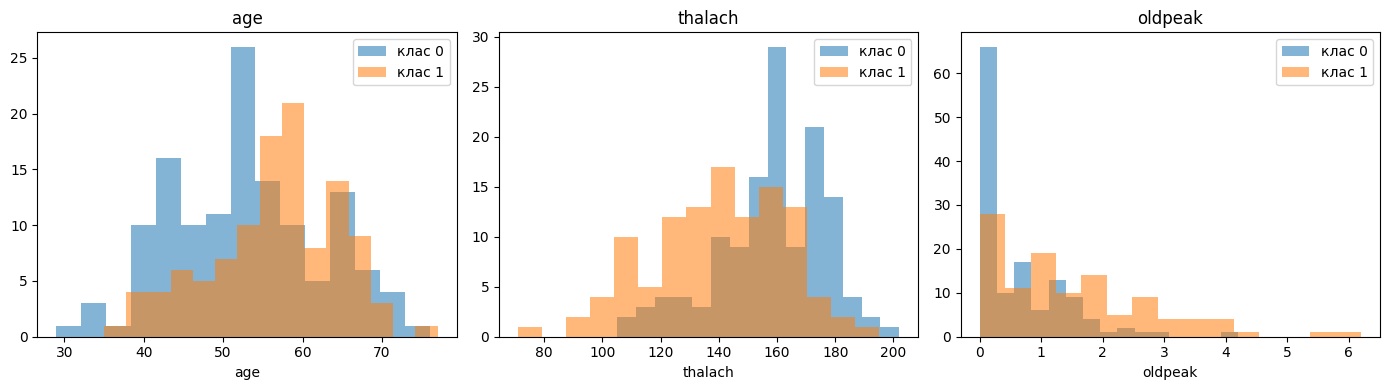

In [70]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["age", "thalach", "oldpeak"]):
    for cls, color in [(0, "tab:blue"), (1, "tab:orange")]:
        ax.hist(X_train.loc[y_train == cls, col].dropna(), bins=15,
                alpha=0.55, label=f"клас {cls}", color=color)
    ax.set_title(col); ax.set_xlabel(col); ax.legend()
plt.tight_layout()
plt.show()

Позавибіркові (OOF) ймовірності для кількох train-об'єктів

In [71]:
oof_models = {
    "GaussianNB OOF": make_prob(GaussianNB()),
    "LDA OOF": make_prob(LinearDiscriminantAnalysis()),
    "QDA OOF": make_prob(QuadraticDiscriminantAnalysis(reg_param=best_rp)),
}

oof = {}
for name, pipe in oof_models.items():
    oof[name] = cross_val_predict(pipe, X_train, y_train, cv=cv,
                                  method="predict_proba", n_jobs=1)[:, 1]

oof_df = pd.DataFrame(oof, index=X_train.index)
oof_df.insert(0, "Справжній клас", y_train)
display(oof_df.sample(8, random_state=RANDOM_STATE).round(3))

,Справжній клас,GaussianNB OOF,LDA OOF,QDA OOF
199,1,0.005,0.013,0.191
55,1,1.000,0.998,1.000
110,1,1.000,0.819,0.789
192,1,1.000,0.877,0.951
173,0,0.477,0.251,0.017
98,0,0.002,0.276,0.079
49,0,0.996,0.081,0.123
78,0,0.000,0.103,0.004


Підсумок частини 2 і збереження кандидатів

In [72]:
best_prob_name = best_prob_row["Модель"]
best_prob_params = best_prob_row["Параметри"]

if best_prob_name.startswith("QDA"):
    best_prob_pipe = make_prob(QuadraticDiscriminantAnalysis(reg_param=best_rp))
elif best_prob_name == "LDA":
    best_prob_pipe = make_prob(LinearDiscriminantAnalysis())
else:
    best_prob_pipe = make_prob(GaussianNB())

cv_rows.append(cv_summary(best_prob_pipe, best_prob_name.split(" ")[0], best_prob_params, n_jobs=1))
display(pd.DataFrame(cv_rows).round(4))

,Модель,Параметри,CV F1,CV F1 std,CV Recall,CV ROC AUC,"Час fit, с"
0,Logistic Regression,"L2, C=10",0.8363,0.0127,0.8016,0.9002,0.0287
1,k-NN,"k=3, metric=manhattan",0.8175,0.0304,0.7917,0.8768,0.0261
2,LDA,solver=svd,0.8128,0.0257,0.7656,0.8993,0.0209


## Висновок
Усі моделі побудовано як Pipeline з однією схемою StratifiedKFold(5) лише на train; тестова вибірка не використовувалася.

- **k-NN:** стандартизація критична: CV F1 зріс з 0,512 до 0,799 (k=5), бо без неї ознаки з великим діапазоном (chol, thalach) домінують у відстані. Найкраще k = 3 (F1 = 0,804), далі F1 монотонно падає до 0,765 (k=15); різниця між сусідніми k менша за std між фолдами. Манхеттенська відстань (F1 = 0,8175) трохи краща за евклідову (0,8042), але різниця в межах шуму. Найкраща k-NN: k=3, manhattan.
- **Ймовірнісні моделі:** найкраща LDA (F1 = 0,8128, ROC AUC = 0,8993, std = 0,026, без попереджень). GaussianNB слабша (F1 = 0,7495) через порушення нормальності (oldpeak) та залежність ознак, але має найвищий Recall (0,846).
- **QDA:** при reg_param=0 нестабільна: 10 попереджень про виродження коваріаційної матриці, F1 = 0,571, std = 0,143. Причина: стовпці one-hot-кодування лінійно залежні. При reg_param=0,01 і 0,1 попередження зникли, найкращий результат за 0,1 (F1 = 0,7962).
- **OOF-ймовірності:** GaussianNB дає надто впевнені, часто помилкові оцінки (наприклад, 0,996 для об'єкта класу 0), LDA стриманіша й надійніша.